In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string
import math

def remove_punc(x):
    t = x.translate(str.maketrans(" "," ",string.punctuation))
    t = t.strip()
    return t

def sigmoid(x, b0, b):
    z = b0 + np.dot(x, b)
    x = 1 / (1 + np.exp(-z))
    return x

def predict(X_test):
    p = sigmoid(X_test, b0, b)
    return p>0.5

def gde(b0, b):
    x = sigmoid(features, b0, b)
    b0 -= alpha*np.sum(x - labels)/m
    b -= alpha*np.dot(features.T, (x- labels))/m
    return b0, b



np.set_printoptions(threshold=np.inf)
df = pd.read_csv("emails.csv")
df1 = df.drop(["Email No.", "Prediction"], axis = 1)

max_iterations = 1000


X = df1
Y = df['Prediction']


X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.4,random_state=1)
log_reg = LogisticRegression(max_iter = max_iterations)

labels = Y_train
features = X_train #df1
featureNames = df1.keys()

features = features.astype(np.float64)

mean = features.mean(axis=0)
std = features.std(axis=0)
std[std == 0] = 1

features = (features - mean) / std


b0 = np.zeros((1))
b = np.zeros((features.shape[1])) 
alpha = 0.01
e = math.e
m = features.shape[0]

log_reg.fit(X_train,Y_train)

Y_pred = log_reg.predict(X_test)
for i in range(max_iterations):
    b0, b = gde(b0, b)
    

X_test = X_test.astype(np.float64)
X_test = (X_test - mean) / std

preddf = predict(X_test)
y_pred = pd.Series(preddf)

print("Accuracy for sklearn: ", metrics.accuracy_score(Y_test, Y_pred))
print("Accuracy for My model: ", metrics.accuracy_score(Y_test, y_pred))

Accuracy for sklearn:  0.9690671822136298
Accuracy for My model:  0.957467375543741


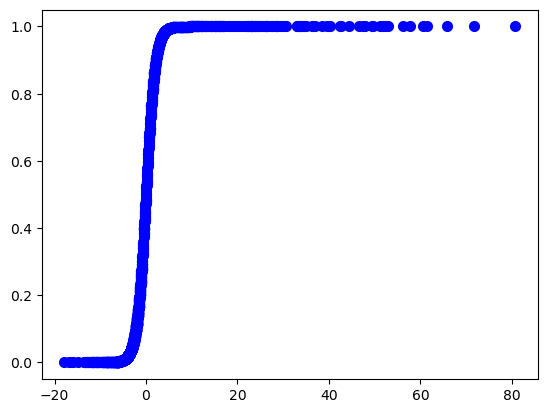

In [16]:
x = b0 + np.dot(features, b)
y = sigmoid(features, b0, b)

plt.scatter(x,y,label="Sigmoid Curve", color="blue", linewidth=2)


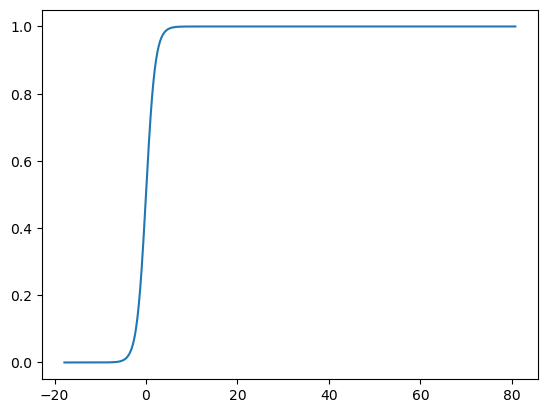

In [17]:
xmin, xmax = x.min(), x.max()
xplot = np.linspace(xmin, xmax, 1000)
yplot = 1/(1+np.exp(-xplot))

plt.plot(xplot, yplot)